### 1. Configuración inicial

In [ ]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 20)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = RAIZ / "data" / "raw"
assert RAW.exists(), f"No encuentro {RAW}. ¿Hiciste `dvc pull`?"

COLOR = {"real": "#2a78d6", "falsa": "#eb6834"}

print("pandas", pd.__version__)
print("Datos crudos en:", RAW)

pandas 3.0.6
Datos crudos en: c:\Proyectos\proyecto-final-APPR\data\raw


In [6]:
def resumen(df: pd.DataFrame) -> pd.DataFrame:
    """Diccionario técnico de una tabla: tipo, nulos y valores distintos por columna."""
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": (df.isna().mean() * 100).round(1),
        "valores distintos": df.nunique(),
    })


def longitudes(texto: pd.Series) -> pd.DataFrame:
    """Longitud de cada texto en caracteres y en palabras (separadas por espacios)."""
    t = texto.fillna("").astype(str)
    return pd.DataFrame({"caracteres": t.str.len(), "palabras": t.str.split().str.len()})


def clave(texto: pd.Series, n: int = 200) -> pd.Series:
    """Versión normalizada del texto (minúsculas, espacios simples, primeros n caracteres) para detectar duplicados."""
    return texto.fillna("").astype(str).str.lower().str.split().str.join(" ").str[:n]


def histograma_longitud(df: pd.DataFrame, col_texto: str, col_clase: str, titulo: str, max_palabras=None):
    """Histograma de palabras por noticia, una serie por clase (real / falsa)."""
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for clase, color in COLOR.items():
        palabras = longitudes(df.loc[df[col_clase] == clase, col_texto])["palabras"]
        if max_palabras:
            palabras = palabras.clip(upper=max_palabras)
        ax.hist(palabras, bins=40, alpha=0.6, color=color, label=f"{clase} (n={len(palabras)})")
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("palabras por noticia" + (f" (recortado en {max_palabras})" if max_palabras else ""))
    ax.set_ylabel("noticias")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

### 2. Integridad de datos

In [31]:
ESPERADO_MD5 = {
    "posadas_duran/train.xlsx": {"bc223bb5f28e71b5a7f317af7bfe88c4"},
    "posadas_duran/development.xlsx": {"56a2afbcdbe49207a958aec14dc0f2bb"},
    "posadas_duran/test.xlsx": {"a375302bb0a27267448157a8015aaa10"},
    "tretiakov/train.csv": {"9b4e50d46496d79fd8e96d50e53cddc6", "7004d1bdbedd9a98c3b0e419756721cf"},
}
ESPERADO_BYTES = {
    "bisaillon/Fake.csv": 62_789_876,
    "bisaillon/True.csv": 53_582_940,
    "ukani/news_datasets.csv": 30_696_129,
}


def md5(ruta: Path) -> str:
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


filas = []
for ruta in sorted(RAW.rglob("*")):
    if not ruta.is_file() or ruta.name.startswith(".") or ruta.suffix in {".dvc", ".gitignore"}:
        continue
    rel = ruta.relative_to(RAW).as_posix()
    huella = md5(ruta)
    if rel in ESPERADO_MD5:
        estado = "OK" if huella in ESPERADO_MD5[rel] else "¡MD5 DISTINTO!"
    elif rel in ESPERADO_BYTES:
        estado = "OK (tamaño)" if ruta.stat().st_size == ESPERADO_BYTES[rel] else "¡TAMAÑO DISTINTO!"
    else:
        estado = "sin referencia"
    filas.append({"archivo": rel, "MB": round(ruta.stat().st_size / 1e6, 2), "md5": huella})

inventario = pd.DataFrame(filas)
inventario

,archivo,MB,md5
0,bisaillon/dataset-metadata.json,0.00,b764b86a2e06d6f02e08573c4c95d69d
1,bisaillon/Fake.csv,62.79,edcb323a8ed3e9f4d5d84016553009eb
2,bisaillon/True.csv,53.58,4c3c571205b62c7591c451cfe60d6af1
3,posadas_duran/development.xlsx,0.36,56a2afbcdbe49207a958aec14dc0f2bb
4,posadas_duran/test.xlsx,0.92,a375302bb0a27267448157a8015aaa10
5,posadas_duran/train.xlsx,0.75,bc223bb5f28e71b5a7f317af7bfe88c4
6,tretiakov/dataset-metadata.json,0.00,6fd2726aeedf1efd06bec2a27dff0022
7,tretiakov/fakes1000.csv,0.50,14a97b224a3d3bd474f6ae22b414f233
8,tretiakov/onlyfakes1000.csv,0.24,600dff522dae832a984d71a71f0eff8a
9,tretiakov/onlytrue1000.csv,0.24,de897afcf0114ac55b93309e63412125


### Datos: Posadas - Durán

In [8]:
pos_train = pd.read_excel(RAW / "posadas_duran" / "train.xlsx")
pos_val = pd.read_excel(RAW / "posadas_duran" / "development.xlsx")
posadas = pd.concat(
    [pos_train.assign(archivo="train"), pos_val.assign(archivo="development")], ignore_index=True
)
print("train:", pos_train.shape)
print("validation:", pos_val.shape) 
print("total:", posadas.shape)
resumen(posadas)

train: (676, 7)
validation: (295, 7)
total: (971, 8)


,tipo,nulos,% nulos,valores distintos
Id,int64,0,0.0,676
Category,str,0,0.0,2
Topic,str,0,0.0,9
Source,str,0,0.0,167
Headline,str,0,0.0,969
Text,str,0,0.0,966
Link,str,0,0.0,969
archivo,str,0,0.0,2


In [9]:
# Balance de clases por archivo
pd.crosstab(posadas["archivo"], posadas["Category"], margins=True, margins_name="total")

Category,Fake,True,total
archivo,,,
development,142,153,295
train,338,338,676
total,480,491,971


In [11]:
# Temas y medios
display(pd.crosstab(posadas["Topic"], posadas["Category"]))

medios = pd.crosstab(posadas["Source"].str.strip().str.lower(), posadas["Category"])
medios["solo_un_tipo"] = (medios[["Fake", "True"]] == 0).any(axis=1)
print(f"Medios distintos: {len(medios)}; medios que publican una sola clase: {medios['solo_un_tipo'].mean():.0%}")
medios.sort_values(["Fake", "True"], ascending=False).head(10)

Category,Fake,True
Topic,,
Economy,19,24
Education,12,10
Entertainment,78,70
Health,23,23
Politics,148,175
Science,43,46
Security,25,17
Society,74,60
Sport,58,66


Medios distintos: 150; medios que publican una sola clase: 98%


Category,Fake,True,solo_un_tipo
Source,,,
el dizque,135,0,True
el ruinaversal,94,0,True
hay noticia,39,0,True
censura 0,36,0,True
la voz popular,24,0,True
modo noticia,22,0,True
retroceso,17,0,True
el mundo today,11,0,True
argumento político,9,0,True


clase               falsa     real
caracteres count    480.0    491.0
           mean    1811.0   2886.0
           std      947.0   2104.0
           min      124.0    326.0
           25%     1250.0   1578.0
           50%     1622.0   2341.0
           75%     2290.0   3500.0
           max    10035.0  15344.0
palabras   count    480.0    491.0
           mean     304.0    474.0
           std      158.0    347.0
           min       20.0     51.0
           25%      211.0    260.0
           50%      274.0    383.0
           75%      384.0    570.0
           max     1672.0   2566.0

Noticias cuyo Text empieza con el titular: 97.4%
Noticias con el marcador *NUMBER*: 77.1%


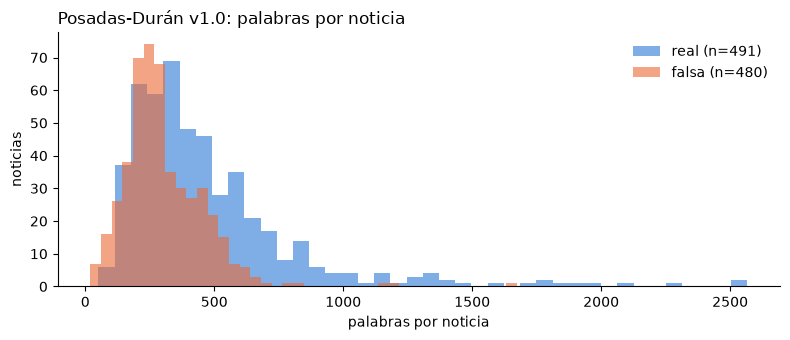

In [12]:
# Longitud de las noticias y dos particularidades del texto
posadas = posadas.assign(clase=posadas["Category"].map({"True": "real", "Fake": "falsa"}))
display(longitudes(posadas["Text"]).groupby(posadas["clase"]).describe().T.round(0))

empieza_con_titular = posadas.apply(
    lambda r: str(r["Text"]).strip().startswith(str(r["Headline"]).strip()[:30]), axis=1
)
print(f"Noticias cuyo Text empieza con el titular: {empieza_con_titular.mean():.1%}")
con_number = posadas["Text"].str.contains(r"\*NUMBER\*", regex=True)
print(f"Noticias con el marcador *NUMBER*: {con_number.mean():.1%}")

histograma_longitud(posadas, "Text", "clase", "Posadas-Durán v1.0: palabras por noticia")

In [13]:
# Duplicados: Id repetidos (por la numeración por archivo) y textos repetidos
print("Id repetidos entre train y development:", posadas["Id"].duplicated().sum())
dup = posadas[clave(posadas["Text"]).duplicated(keep=False)].sort_values("Text")
print("Noticias con texto repetido:", len(dup), "(es decir", clave(posadas["Text"]).duplicated().sum(), "sobrantes)")
dup[["archivo", "Id", "Category", "Source"]]

Id repetidos entre train y development: 295
Noticias con texto repetido: 12 (es decir 6 sobrantes)


,archivo,Id,Category,Source
277,train,278,Fake,El Dizque
740,development,65,Fake,El Ruinaversal
942,development,267,True,HUFFPOST
461,train,462,True,HUFFPOST
804,development,129,Fake,Hay noticia
822,development,147,Fake,Hay noticia
171,train,172,True,Aristegui noticias
852,development,177,True,Forbes
251,train,252,Fake,El Ruinaversal
694,development,19,Fake,El Dizque


### Posada-Durán 2020-2021

In [14]:
pos_v2 = pd.read_excel(RAW / "posadas_duran" / "test.xlsx")
print(pos_v2.shape)
display(resumen(pos_v2))
display(pos_v2["CATEGORY"].value_counts())
pos_v2["TOPICS"].value_counts()

(572, 7)


,tipo,nulos,% nulos,valores distintos
ID,int64,0,0.0,572
CATEGORY,bool,0,0.0,2
TOPICS,str,0,0.0,7
SOURCE,str,7,1.2,205
HEADLINE,str,72,12.6,500
TEXT,str,0,0.0,572
LINK,str,3,0.5,569


CATEGORY
True     286
False    286
Name: count, dtype: int64

TOPICS
Covid-19         237
Sociedad         195
Política         107
Internacional     14
Ciencia           13
Ambiental          4
Deporte            2
Name: count, dtype: int64

### Tretiakov (español)

In [15]:
tret = pd.read_csv(RAW / "tretiakov" / "train.csv")
print(tret.shape)
display(resumen(tret))
tret["label"].value_counts()

(1600, 3)


,tipo,nulos,% nulos,valores distintos
title,str,498,31.1,1059
text,str,0,0.0,1566
label,int64,0,0.0,2


label
1    800
0    800
Name: count, dtype: int64

Clasificación en conjunto de datos

In [ ]:
solo_falsas = pd.read_csv(RAW / "tretiakov" / "onlyfakes1000.csv")
solo_reales = pd.read_csv(RAW / "tretiakov" / "onlytrue1000.csv")
fakes1000 = pd.read_csv(RAW / "tretiakov" / "fakes1000.csv")

k = clave(tret["text"], 120)
origen = pd.Series("no aparece", index=tret.index)
origen[k.isin(set(clave(solo_falsas["text"], 120)))] = "onlyfakes1000"
origen[k.isin(set(clave(solo_reales["text"], 120)))] = "onlytrue1000"
display(pd.crosstab(tret["label"], origen))

clase_1000 = k.map(dict(zip(clave(fakes1000["Text"], 120), fakes1000["class"])))
pd.crosstab(tret["label"], clase_1000.fillna("no aparece"), colnames=["class en fakes1000"])

col_0,onlyfakes1000,onlytrue1000
label,,
0,0,800
1,800,0


class en fakes1000,False,True
label,,
0,0,800
1,800,0


Calidad el texto

clase              falsa    real
caracteres count   800.0   800.0
           mean    235.0   236.0
           std      87.0    88.0
           min      38.0    50.0
           25%     254.0   254.0
           50%     255.0   255.0
           75%     255.0   255.0
           max    2052.0  2249.0
palabras   count   800.0   800.0
           mean     40.0    40.0
           std      15.0    15.0
           min       6.0     7.0
           25%      39.0    39.0
           50%      42.0    42.0
           75%      45.0    44.0
           max     364.0   379.0

Textos con 250 caracteres o más: 80%
Textos con exactamente 255 caracteres: 73%


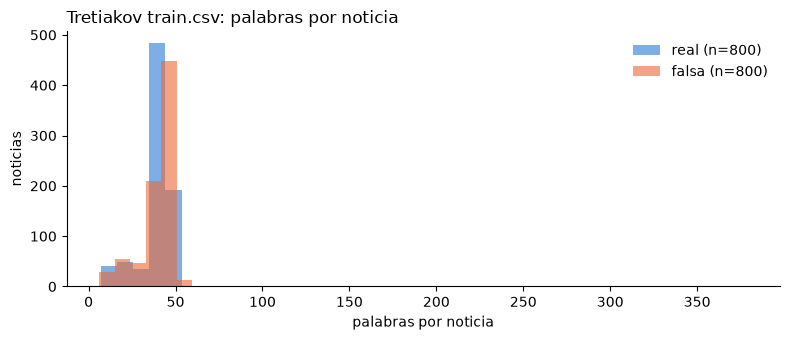

In [ ]:
tret = tret.assign(clase=tret["label"].map({0: "real", 1: "falsa"}))
long_t = longitudes(tret["text"])
display(long_t.groupby(tret["clase"]).describe().T.round(0))
print(f"Textos con 250 caracteres o más: {(long_t['caracteres'] >= 250).mean():.0%}")
print(f"Textos con exactamente 255 caracteres: {(long_t['caracteres'] == 255).mean():.0%}")

histograma_longitud(tret, "text", "clase", "Tretiakov train.csv: palabras por noticia")

In [ ]:
print("Títulos vacíos:", tret["title"].isna().sum())
print("Títulos repetidos:", tret["title"].duplicated().sum())
print("Textos repetidos:", clave(tret["text"]).duplicated().sum())
print("Textos repetidos con etiqueta distinta:",
      tret.assign(k=clave(tret["text"])).groupby("k")["label"].nunique().gt(1).sum())

otros = {f: pd.read_csv(RAW / "tretiakov" / f).shape for f in ["test.csv", "fakes1000.csv", "onlyfakes1000.csv", "onlytrue1000.csv"]}
otros

Títulos vacíos: 498
Títulos repetidos: 540
Textos repetidos: 44
Textos repetidos con etiqueta distinta: 0


{'test.csv': (400, 2),
 'fakes1000.csv': (2000, 2),
 'onlyfakes1000.csv': (1000, 1),
 'onlytrue1000.csv': (1000, 1)}

### Duplicados de texto en español

In [ ]:
inicio_tret = tret["text"].str.strip().str[:80]
todo_posadas = "\n".join(posadas["Text"].astype(str))
en_posadas = inicio_tret.apply(lambda s: s in todo_posadas)
print("Noticias de Tretiakov que también están en Posadas v1.0:", en_posadas.sum())

cruces = []
for i in tret.index[en_posadas]:
    fila_p = posadas[posadas["Text"].str.contains(inicio_tret[i], regex=False)].iloc[0]
    cruces.append({"tretiakov_label": tret.at[i, "label"], "posadas_Category": fila_p["Category"],
                   "posadas_Source": fila_p["Source"]})
pd.DataFrame(cruces)

Noticias de Tretiakov que también están en Posadas v1.0: 4


,tretiakov_label,posadas_Category,posadas_Source
0,1,Fake,Hay noticia
1,1,Fake,Hay noticia
2,1,Fake,Hay noticia
3,1,Fake,Alerta digital


### Bisaillon 

In [ ]:
bis_fake = pd.read_csv(RAW / "bisaillon" / "Fake.csv")
bis_true = pd.read_csv(RAW / "bisaillon" / "True.csv")
bisaillon = pd.concat([bis_fake.assign(clase="falsa"), bis_true.assign(clase="real")], ignore_index=True)

conteo = bisaillon["clase"].value_counts().rename("ahora").to_frame()
conteo["artículo"] = pd.Series({"falsa": 23_481, "real": 21_417})
conteo["diferencia"] = conteo["ahora"] - conteo["artículo"]
display(conteo)
resumen(bisaillon)

,ahora,artículo,diferencia
clase,,,
falsa,23481,23481,0
real,21417,21417,0


,tipo,nulos,% nulos,valores distintos
title,str,0,0.0,38729
text,str,0,0.0,38646
subject,str,0,0.0,8
date,str,0,0.0,2397
clase,str,0,0.0,2


In [ ]:
display(pd.crosstab(bisaillon["subject"], bisaillon["clase"]))

fechas = pd.to_datetime(bisaillon["date"].str.strip(), errors="coerce", format="mixed")
print("Fechas no interpretables:", fechas.isna().sum())
print("Rango de fechas:", fechas.min().date(), "a", fechas.max().date())

clase,falsa,real
subject,,
Government News,1570,0
Middle-east,778,0
News,9050,0
US_News,783,0
left-news,4459,0
politics,6841,0
politicsNews,0,11272
worldnews,0,10145


Fechas no interpretables: 10
Rango de fechas: 2015-03-31 a 2018-02-19


Textos vacíos por clase: {'falsa': 630, 'real': 1}
Textos repetidos: 6008


contiene '(Reuters)' al inicio,False,True
clase,,
falsa,1.000,0.000
real,0.013,0.987


clase               falsa     real
caracteres count  23481.0  21417.0
           mean    2547.0   2383.0
           std     2533.0   1685.0
           min        1.0      1.0
           25%     1433.0    914.0
           50%     2166.0   2222.0
           75%     3032.0   3237.0
           max    51794.0  29781.0
palabras   count  23481.0  21417.0
           mean     423.0    386.0
           std      408.0    274.0
           min        0.0      0.0
           25%      240.0    148.0
           50%      363.0    359.0
           75%      506.0    525.0
           max     8135.0   5172.0

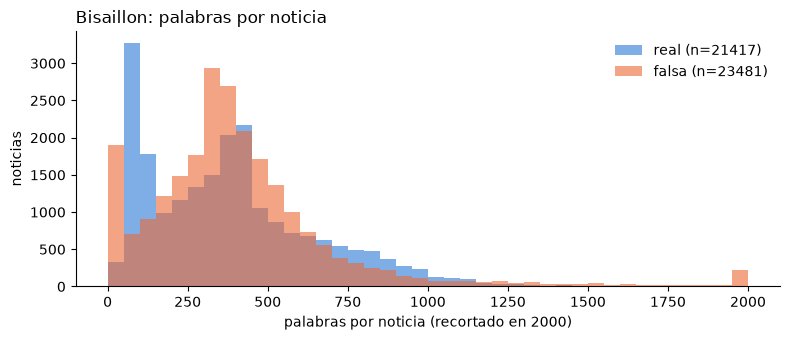

In [ ]:
vacio = bisaillon["text"].fillna("").str.strip().eq("")
print("Textos vacíos por clase:", bisaillon.loc[vacio, "clase"].value_counts().to_dict())
print("Textos repetidos:", clave(bisaillon["text"]).loc[~vacio].duplicated().sum())

reuters = bisaillon["text"].fillna("").str[:120].str.contains(r"\(Reuters\)", regex=True)
display(pd.crosstab(bisaillon["clase"], reuters, colnames=["contiene '(Reuters)' al inicio"], normalize="index").round(3))

display(longitudes(bisaillon["text"]).groupby(bisaillon["clase"]).describe().T.round(0))
histograma_longitud(bisaillon, "text", "clase", "Bisaillon: palabras por noticia", max_palabras=2000)

### Ukani

In [ ]:
ukani = pd.read_csv(RAW / "ukani" / "news_datasets.csv")
print(ukani.shape)
resumen(ukani)

(6335, 4)


,tipo,nulos,% nulos,valores distintos
Unnamed: 0,int64,0,0.0,6335
title,str,0,0.0,6256
text,str,0,0.0,6060
label,str,0,0.0,2


In [ ]:
col_label = next((c for c in ukani.columns if c.strip().lower() in {"label", "class", "category"}), None)
print("Columna de etiqueta:", col_label)
if col_label:
    display(ukani[col_label].value_counts(dropna=False))

col_texto = next((c for c in ukani.columns if c.strip().lower() in {"text", "body", "content"}), None)
print("Columna de texto:", col_texto)
if col_texto:
    print("Textos vacíos:", ukani[col_texto].fillna("").str.strip().eq("").sum())
    print("Textos repetidos:", clave(ukani[col_texto]).duplicated().sum())
    display(longitudes(ukani[col_texto]).describe().T.round(0))

Columna de etiqueta: label


label
REAL    3171
FAKE    3164
Name: count, dtype: int64

Columna de texto: text
Textos vacíos: 36
Textos repetidos: 299


,count,mean,std,min,25%,50%,75%,max
caracteres,6335.0,4707.0,5091.0,1.0,1742.0,3642.0,6192.0,115372.0
palabras,6335.0,776.0,854.0,0.0,289.0,597.0,1024.0,20891.0


### Conclusiones

In [29]:
def fila_resumen(nombre, idioma, uso, df, col_clase, falsa, real):
    return {"tabla": nombre, "idioma": idioma, "uso": uso, "filas": len(df),
            "falsas": int((df[col_clase] == falsa).sum()), "reales": int((df[col_clase] == real).sum())}

tabla = [
    fila_resumen("Posadas v1.0 (train+development)", "es", "réplica", posadas, "Category", "Fake", "True"),
    fila_resumen("Tretiakov train.csv", "es", "réplica", tret, "label", 1, 0),
    fila_resumen("Posadas v2.0 (test.xlsx)", "es", "prueba de generalización", pos_v2, "CATEGORY", False, True),
    fila_resumen("Bisaillon Fake+True", "en", "modelo B", bisaillon, "clase", "falsa", "real"),
]
if col_label:
    etiquetas = ukani[col_label].astype(str).str.upper()
    tabla.append({"tabla": "Ukani news_datasets.csv", "idioma": "en", "uso": "modelo B", "filas": len(ukani),
                  "falsas": int(etiquetas.isin(["FAKE", "1"]).sum()), "reales": int(etiquetas.isin(["REAL", "0"]).sum())})

resumen_tablas = pd.DataFrame(tabla)
resumen_tablas

,tabla,idioma,uso,filas,falsas,reales
0,Posadas v1.0 (train+development),es,réplica,971,480,491
1,Tretiakov train.csv,es,réplica,1600,800,800
2,Posadas v2.0 (test.xlsx),es,prueba de generalización,572,286,286
3,Bisaillon Fake+True,en,modelo B,44898,23481,21417
4,Ukani news_datasets.csv,en,modelo B,6335,3164,3171


In [30]:
# Corpus en español de la réplica, antes de limpiar: debería dar 2571 filas (1280 falsas y 1291 reales)
es = resumen_tablas[resumen_tablas["uso"] == "réplica"][["filas", "falsas", "reales"]].sum()
es

filas     2571
falsas    1280
reales    1291
dtype: int64